# Know Which Evidence Came from OCR

Tell born-digital text from OCR text layers and from text that exists only in images, and mark OCR evidence for review. Steps 2 and 3 need Tesseract.

Companion notebook for the article [Know Which Evidence Came from OCR](https://pymupdf.io/blog/know-which-evidence-came-from-ocr) in the PyMuPDF grounding series. Tested with PyMuPDF 2.1.

In [20]:
%pip install -q pymupdf
# OCR needs Tesseract. On Colab or Debian/Ubuntu:
#!apt-get -qq install -y tesseract-ocr > /dev/null
# On macOS: brew install tesseract


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Sample document
Creates the sample PDF used in the article. Replace the path with your own PDF to try it on real documents.

In [21]:
import pymupdf

def text_image(text, width=400, fontsize=11, dpi=200, rotate_noise=False):
    """Render text to an image, like a scanned paragraph."""
    tmp = pymupdf.open()
    p = tmp.new_page(width=width + 20, height=200)
    p.insert_textbox(pymupdf.Rect(10, 10, width + 10, 190), text, fontsize=fontsize, fontname="tiro")
    tp = p.get_textpage()
    bb = pymupdf.Rect()
    for b in p.get_text("blocks"):
        bb |= pymupdf.Rect(b[:4])
    clip = bb + (-6, -6, 6, 6)
    return p.get_pixmap(dpi=dpi, clip=clip, colorspace=pymupdf.csGRAY), clip

doc = pymupdf.open()
# Page 1: born-digital text plus one scanned paragraph pasted in as an image
page = doc.new_page()
page.insert_text((72, 90), "Acme Corporation Annual Report 2025", fontsize=16, fontname="hebo")
page.insert_textbox(pymupdf.Rect(72, 110, 500, 200),
    "Net revenue increased 12% to $4.1 billion, driven by growth in the enterprise software segment. "
    "Operating margin improved to 18.4%, compared with 16.9% in the prior year.", fontsize=11, fontname="helv")
page.insert_text((72, 225), "Appendix: signed auditor's statement (scanned)", fontsize=11, fontname="hebo")
pix, clip = text_image("We have audited the consolidated financial statements of Acme Corporation. "
                       "In our opinion, the statements present fairly, in all material respects, "
                       "the financial position of the company as of December 31, 2025.")
page.insert_image(pymupdf.Rect(72, 235, 72 + clip.width, 235 + clip.height), pixmap=pix)

# Page 2: a fully scanned page that already has an OCR text layer (as scanners produce)
scan = pymupdf.open()
sp = scan.new_page()
sp.insert_text((72, 90), "Board of Directors' report", fontsize=16, fontname="tibo")
sp.insert_textbox(pymupdf.Rect(72, 110, 500, 300),
    "The Board approved a dividend of $1.20 per share, payable in March 2026. "
    "The Board also authorized a share repurchase program of up to $500 million.", fontsize=11, fontname="tiro")
spix = sp.get_pixmap(dpi=200)
ocr_pdf = pymupdf.open("pdf", spix.pdfocr_tobytes(language="eng", tessdata="/opt/homebrew/share/tessdata")) # edit the tessdata path if needed
doc.insert_pdf(ocr_pdf)
doc.save("acme_mixed.pdf")

## Grounding helpers
`locate()` comes from the first article in the series, [Cite Claude's Answers at the Exact Spot in the PDF](https://pymupdf.io/blog/cite-claude-answers-at-the-exact-spot-in-the-pdf). It is also part of [the PyMuPDF grounding skill](https://github.com/pymupdf/cookbook/tree/main/skills/grounding-skill).

In [22]:
import re
import pymupdf


def locate(page, cited_text):
    """Return the quads of cited_text on a page, or [] if not found."""
    text = " ".join(cited_text.split())          # collapse whitespace and line breaks
    quads = page.search_for(text, quads=True)    # case-insensitive, joins hyphenated words
    if quads:
        return quads
    return _locate_by_words(page, text)          # fallback for small differences


def _norm(word):
    return re.sub(r"[^\w%$.]", "", word).lower().rstrip(".")


def _locate_by_words(page, text):
    """Match the quote word by word, ignoring punctuation, case and hyphenation."""
    target = [_norm(w) for w in text.split() if _norm(w)]
    words = page.get_text("words", flags=pymupdf.TEXT_DEHYPHENATE)
    tokens = [(_norm(w[4]), pymupdf.Rect(w[:4])) for w in words]
    tokens = [t for t in tokens if t[0]]
    n = len(target)
    for i in range(len(tokens) - n + 1):
        if all(tokens[i + k][0] == target[k] for k in range(n)):
            return [r.quad for _, r in tokens[i:i + n]]
    return []

## Step 1: Tell native text from an OCR layer

An OCR text layer is drawn with text render mode 3, which makes it invisible: you see the scanned image, and the text sits on top for searching and copying. Page.get_texttrace() reports the render type of every span, and type 3 means invisible. OCR layers also commonly use a placeholder font called GlyphLessFont.

In [23]:
def text_source(page, rect):
    """Where the text in rect comes from: 'native', 'ocr-layer', 'mixed' or 'none'.

    'ocr-layer' is invisible text placed over a scanned image, as produced by
    scanners and OCR tools. It is searchable, but it is only as good as that OCR.
    """
    visible = invisible = 0
    for span in page.get_texttrace():
        if not pymupdf.Rect(span["bbox"]).intersects(rect):
            continue
        n = len(span["chars"])
        if span["type"] == 3:              # text render mode 3: invisible
            invisible += n
        else:
            visible += n
    if visible and invisible:
        return "mixed"
    if invisible:
        return "ocr-layer"
    return "native" if visible else "none"

## Step 2: Find text that only exists in an image

If a quote is not in the text layer, it may still be on the page, inside an image. Page.get_textpage_ocr(full=False) runs OCR only on the page's images and combines the result with the native text, so we can search again. This needs Tesseract installed.

In [24]:
def locate_with_source(page, text, ocr_language="eng"):
    """Locate text and report where the evidence comes from.

    Returns (quads, source). Text that exists only inside an image is found by
    running OCR on the page's images, and reported as 'ocr-runtime'.
    """
    quads = locate(page, text)
    if quads:
        box = pymupdf.Rect()
        for q in quads:
            box |= q.rect
        return quads, text_source(page, box)
    tp = page.get_textpage_ocr(full=False, dpi=300, language=ocr_language, tessdata="/opt/homebrew/share/tessdata") # edit the tessdata path if needed
    quads = page.search_for(" ".join(text.split()), quads=True, textpage=tp)
    return quads, ("ocr-runtime" if quads else "not-found")

`locate()` is the function from [the first article in this series](https://pymupdf.io/blog/cite-claude-answers-at-the-exact-spot-in-the-pdf); it is also in [the grounding skill's helper script](https://github.com/pymupdf/cookbook/tree/main/skills/grounding-skill). Running the sample document through it:

In [25]:
doc = pymupdf.open("acme_mixed.pdf")
for page_index, quote in [
    (0, "Net revenue increased 12% to $4.1 billion"),
    (0, "In our opinion, the statements present fairly"),
    (1, "The Board approved a dividend of $1.20 per share"),
    (0, "Revenue in Asia doubled"),
]:
    quads, source = locate_with_source(doc[page_index], quote)
    print(page_index + 1, f"{source:13}", quote)

1 native        Net revenue increased 12% to $4.1 billion
1 ocr-runtime   In our opinion, the statements present fairly
2 ocr-layer     The Board approved a dividend of $1.20 per share
1 not-found     Revenue in Asia doubled


The revenue figure is native text. The auditor's opinion exists only as an image and was found by OCR. The dividend is in an OCR text layer from a scanner: a citation tool would treat it like any other text, so without this check nobody would know it came from a scan. The last quote is not in the document at all.

## Step 3: Mark OCR evidence for review

Show the reader the difference. Here native evidence is highlighted in yellow and OCR evidence in orange, and the document is left unchanged:

In [26]:
COLORS = {"native": (1, 1, 0), "ocr-layer": (1, 0.6, 0.2), "ocr-runtime": (1, 0.6, 0.2),
          "mixed": (1, 0.6, 0.2)}

In [27]:
def evidence_image(page, quads, source, margin=24, dpi=150):
    """Render the evidence, highlighted yellow for native text and orange for OCR text."""
    box = pymupdf.Rect()
    for q in quads:
        box |= q.rect
    clip = (box + (-margin, -margin, margin, margin)) & page.rect
    annot = page.add_highlight_annot(quads)
    annot.set_colors(stroke=COLORS.get(source, (1, 1, 0)))
    annot.update()
    pix = page.get_pixmap(clip=clip, dpi=dpi)
    page.delete_annot(annot)
    return pix

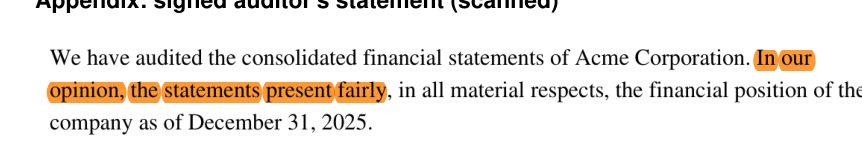

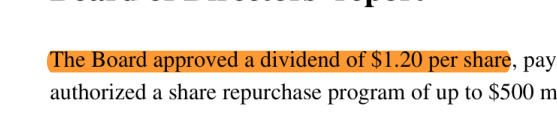

In [28]:
from IPython.display import Image, display
for page_index, quote in [(0, "In our opinion, the statements present fairly"),
                          (1, "The Board approved a dividend of $1.20 per share")]:
    page = doc[page_index]
    quads, source = locate_with_source(page, quote)
    display(Image(evidence_image(page, quads, source).tobytes("png")))

In an answer or an evidence pack, add a short note next to OCR evidence, such as "Read from a scanned image: check against the original." The highlight in the second image ends slightly before the last word. That is typical of OCR layers: their text positions are estimates, so the highlight may not line up exactly with the image.

## Step 4: Check a whole document before indexing

Before a document goes into a RAG index or an AI workflow, it helps to know what it contains. This report counts native and OCR-layer characters per page and lists images that have no text over them, which may be scans that need OCR:

In [29]:
def page_report(page):
    """Count native and OCR-layer characters, and find images that hold no text layer."""
    native = ocr_layer = 0
    for span in page.get_texttrace():
        if span["type"] == 3:
            ocr_layer += len(span["chars"])
        else:
            native += len(span["chars"])
    text_area = [pymupdf.Rect(s["bbox"]) for s in page.get_texttrace()]
    untexted_images = []
    for xref, *_ in page.get_images():
        for rect in page.get_image_rects(xref):
            if not any(rect.intersects(t) for t in text_area):
                untexted_images.append(rect)
    return {"page": page.number + 1, "native_chars": native,
            "ocr_layer_chars": ocr_layer, "images_without_text": untexted_images}

In [30]:
for page in doc:
    print(page_report(page))

{'page': 1, 'native_chars': 250, 'ocr_layer_chars': 0, 'images_without_text': [Rect(73.18086242675781, 235.00057983398438, 476.933837890625, 292.577392578125)]}
{'page': 2, 'native_chars': 0, 'ocr_layer_chars': 146, 'images_without_text': []}


Page 1 is born-digital but contains one image with no text: the scanned auditor's statement. Page 2 is entirely an OCR layer.

## With PyMuPDF's Layout pipeline

`Document.to_markdown()` runs OCR on picture regions automatically when Tesseract is available, and wraps the result in a marker. If you build RAG chunks from `page_boxes`, as in [the second article of this series](https://pymupdf.io/blog/keep-page-coordinates-with-your-rag-chunks), you can flag those chunks as OCR text:

In [31]:
for page_dict in doc.to_markdown(page_chunks=True):
    text = page_dict["text"]
    for box in page_dict["page_boxes"]:
        start, stop = box["pos"]
        if box["class"] == "picture" and "Start of picture text" in text[start:stop]:
            print("OCR text from a picture:", page_dict["metadata"]["page_number"], box["bbox"])

rapidocr_api using backend: rapidocr

=== Document parser messages ===
Using RapidOCR for OCR processing.
OCR on page.number=0/1.


Text from an existing OCR layer, such as page 2 of the sample, is reported as an ordinary text box. To flag it, run `text_source()` on the box's `bbox`.

## Limits to know
- OCR at extraction time needs Tesseract and adds processing time. `full=False` limits it to the page's images.
- OCR text comes back as many small pieces, often one quad per word. Merge them into one rectangle for display.
- Invisible text is almost always an OCR layer, but not always: some documents hide other text. Treat ocr-layer as a strong signal, not proof.
- Claude's citations work from the PDF's text layer. Text that exists only in an image cannot be cited by Claude, so the ocr-runtime case applies to quotes from other sources, such as models that read page images.

## Next steps

- Read the full article: https://pymupdf.io/blog/know-which-evidence-came-from-ocr
- See everything on grounding with PyMuPDF: https://pymupdf.io/grounding